# Modelo autorregresivo tipo GPT (decoder-only)

Se implementa un **Transformer de solo decodificador** (familia GPT) y se entrena con la **tarea pretext** de la unidad: *predecir el siguiente token*. Trabajamos a nivel de carácter sobre un corpus pequeño en español y luego **generamos texto** de forma autorregresiva.

In [1]:
# --- Dependencias (en Colab ya vienen; si no) ---
!pip install torch matplotlib -q

import math, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); random.seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cpu


## Bloques del Transformer desde cero

In [2]:
# ======== Bloques del Transformer construidos DESDE CERO ========
# Cada pieza corresponde a un concepto de la Unidad II.

def scaled_dot_product_attention(Q, K, V, mask=None):
    """Atención escalada por producto punto. Devuelve la salida y los pesos de atención."""
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)      # QKᵀ / √d_k
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))  # padding o máscara causal
    attn = torch.softmax(scores, dim=-1)                      # pesos de atención (suman 1)
    return attn @ V, attn

class MultiHeadAttention(nn.Module):
    """h cabezas en paralelo: proyecta Q,K,V, aplica atención por cabeza y concatena (Wo)."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model); self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model); self.Wo = nn.Linear(d_model, d_model)
    def forward(self, q, k, v, mask=None):
        B = q.size(0)
        split = lambda x: x.view(B, -1, self.h, self.d_k).transpose(1, 2)   # (B,h,L,d_k)
        Q, K, V = split(self.Wq(q)), split(self.Wk(k)), split(self.Wv(v))
        if mask is not None: mask = mask.unsqueeze(1)                       # (B,1,Lq,Lk)
        out, attn = scaled_dot_product_attention(Q, K, V, mask)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.Wo(out), attn                                          # attn: (B,h,Lq,Lk)

class PositionwiseFFN(nn.Module):
    """Red feed-forward position-wise: Linear → ReLU → Linear."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)

class PositionalEncoding(nn.Module):
    """Codificación posicional sinusoidal (se suma al embedding)."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(pos*div); pe[:, 1::2] = torch.cos(pos*div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class EncoderLayer(nn.Module):
    """Self-attention + FFN, cada subcapa con residual + LayerNorm."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads); self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None):
        a, attn = self.attn(x, x, x, mask); x = self.n1(x + self.drop(a))
        x = self.n2(x + self.drop(self.ffn(x)));  return x, attn

class DecoderLayer(nn.Module):
    """Masked self-attention + cross-attention + FFN (residual + LayerNorm)."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.cross_attn = MultiHeadAttention(d_model, n_heads)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2, self.n3 = (nn.LayerNorm(d_model) for _ in range(3)); self.drop = nn.Dropout(dropout)
    def forward(self, x, memory, tgt_mask=None, src_mask=None):
        a, sa = self.self_attn(x, x, x, tgt_mask);      x = self.n1(x + self.drop(a))
        c, ca = self.cross_attn(x, memory, memory, src_mask); x = self.n2(x + self.drop(c))
        x = self.n3(x + self.drop(self.ffn(x)));         return x, sa, ca

def causal_mask(L, device):
    """Máscara triangular: la posición i solo atiende a ≤ i (autorregresivo)."""
    return torch.tril(torch.ones(L, L, device=device)).bool().unsqueeze(0)

print("Bloques del Transformer listos.")

Bloques del Transformer listos.


## Datos: corpus de caracteres

Un corpus chico (autocontenido). La tarea pretext: dado un tramo de texto, predecir el carácter siguiente en cada posición.

In [3]:
texto=("el transformer usa atencion para modelar dependencias entre tokens. "
       "la autoatencion pondera cada token segun su contexto. "
       "el decoder genera texto token a token de forma autorregresiva. "
       "los modelos fundacionales aprenden de grandes corpus sin etiquetas. ")*40
chars=sorted(set(texto)); stoi={c:i for i,c in enumerate(chars)}; itos={i:c for c,i in stoi.items()}
V=len(chars); data=torch.tensor([stoi[c] for c in texto]); BLOCK=48
print("Longitud del corpus:",len(texto),"| vocabulario:",V)
def get_batch(bs=64):
    ix=torch.randint(0,len(data)-BLOCK-1,(bs,))
    x=torch.stack([data[i:i+BLOCK] for i in ix])
    y=torch.stack([data[i+1:i+1+BLOCK] for i in ix])     # objetivo = entrada desplazada 1
    return x.to(device),y.to(device)

Longitud del corpus: 10120 | vocabulario: 22


## Modelo: decoder-only con atención causal

Cada token solo atiende a los anteriores (máscara causal), así que la predicción del token *t* nunca ve el futuro.

In [4]:
class GPT(nn.Module):
    def __init__(self, V, d=96, h=4, ff=256, nl=3):
        super().__init__()
        self.emb=nn.Embedding(V,d); self.pe=PositionalEncoding(d)
        self.layers=nn.ModuleList([DecoderLayer(d,h,ff) for _ in range(nl)])
        self.out=nn.Linear(d,V)
    def forward(self, x, return_attn=False):
        B,T=x.shape; m=causal_mask(T,x.device); h=self.pe(self.emb(x)); att=None
        for l in self.layers:                                  # solo masked self-attention + FFN
            a,att=l.self_attn(h,h,h,m); h=l.n1(h+a); h=l.n3(h+l.ffn(h))
        logits=self.out(h)
        return (logits,att) if return_attn else logits

model=GPT(V).to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 377974


## Entrenamiento (predecir el siguiente token)

In [5]:
opt=torch.optim.Adam(model.parameters(),lr=3e-3); lf=nn.CrossEntropyLoss()
t0=time.time()
for step in range(600):
    x,y=get_batch(); logits=model(x); loss=lf(logits.reshape(-1,V),y.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if (step+1)%150==0: print(f"paso {step+1:4d}  loss {loss.item():.3f}")
print(f"entrenado en {time.time()-t0:.0f}s")

paso  150  loss 0.077
paso  300  loss 0.096
paso  450  loss 0.065
paso  600  loss 0.067
entrenado en 108s


## Generación autorregresiva (con temperatura)

In [6]:
@torch.no_grad()
def generar(prompt="el transformer ", n=180, temp=0.8):
    model.eval(); idx=torch.tensor([[stoi[c] for c in prompt]],device=device)
    for _ in range(n):
        logits=model(idx[:,-BLOCK:])[:,-1]/temp
        p=torch.softmax(logits,-1); nxt=torch.multinomial(p,1)
        idx=torch.cat([idx,nxt],1)
    return "".join(itos[i] for i in idx[0].tolist())
print(generar())

el transformer usa atencion para modelar dependencias entre tokens. la autoatencion pondera cada token segun su contexto. el decoder genera texto token a token de forma autorregresiva. los modelo


## Visualización: la máscara causal en acción

Graficamos la self-attention de la última capa para una secuencia. El patrón **triangular inferior** confirma que cada posición solo atiende a las anteriores.

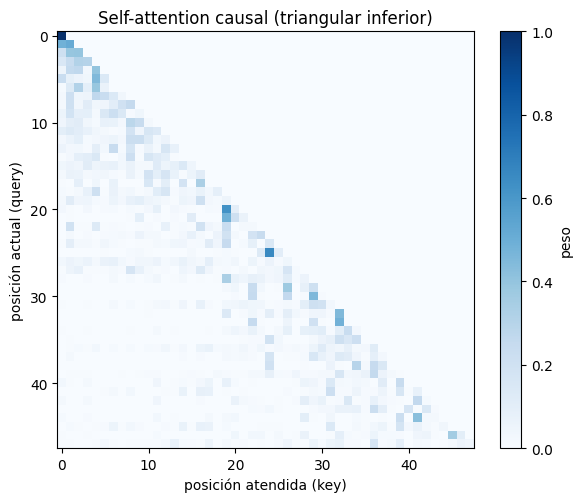

In [7]:
x,_=get_batch(1); _,att=model(x,return_attn=True)
A=att[0].mean(0).detach().cpu().numpy()      # promedio sobre cabezas
plt.figure(figsize=(6,5))
plt.imshow(A,cmap="Blues"); plt.title("Self-attention causal (triangular inferior)")
plt.xlabel("posición atendida (key)"); plt.ylabel("posición actual (query)")
plt.colorbar(label="peso"); plt.tight_layout(); plt.show()

## Conclusión

Un decoder-only entrenado con la tarea pretext de predecir el siguiente token aprende a generar texto — el principio de la familia GPT. La máscara causal garantiza la naturaleza autorregresiva.